# Custom Russian Tokenizer: BPE-токенизатор для русского языка с нуля

**Задача:** обучить собственный токенизатор на русских текстах из корпуса `Helsinki-NLP/opus_books`,
сформировать словарь и сравнить, как он справляется с русской морфологией, по сравнению с готовыми токенизаторами RuBERT.

**Подход:** очистка русской части параллельного корпуса → обучение BPE-токенизатора библиотекой `tokenizers` →
пословное сравнение с `cointegrated/rubert-tiny2` и `DeepPavlov/rubert-base-cased` → метрики (токенов на слово, `[UNK]`) → эксперименты с размером словаря и объёмом корпуса.

**Содержание**
1. Подготовка корпуса
2. Обучение BPE-токенизатора
3. Сравнение с RuBERT и анализ морфологии
4. Метрики: токены на слово и `[UNK]`
5. Отчёт и выводы

**Запуск:** Google Colab (`Runtime → Run all`, GPU не нужен) или локально через Docker (`docker compose up -d`, см. README).

## 0. Подготовка окружения

Обучение токенизатора — это подсчёт частот пар символов, а не обучение нейросети, поэтому PyTorch и GPU не нужны.
В Colab библиотеки `datasets`, `tokenizers` и `transformers` обычно уже установлены, команда ниже доставит их, если чего-то не хватает.
В Docker-образе всё ставится из `requirements.txt`.

In [1]:
import sys

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    !pip install -q datasets tokenizers transformers

Фиксируем `seed`: случайные примеры и отложенная выборка предложений будут одинаковыми при каждом запуске.

In [2]:
import json
import random
import re
import time
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset
from tokenizers import Tokenizer, decoders, models, normalizers, pre_tokenizers, processors, trainers

RANDOM_STATE = 42

random.seed(RANDOM_STATE)

pd.set_option('display.max_colwidth', 120)

## 1. Подготовка корпуса

### 1.1 Загрузка датасета

[`Helsinki-NLP/opus_books`](https://huggingface.co/datasets/Helsinki-NLP/opus_books) — параллельный корпус переводов книг:
каждая строка содержит одно и то же предложение на двух языках. Языковая пара выбирается конфигом, берём `en-ru`.

Датасет скачивается с Hugging Face Hub при первом запуске и кэшируется на диске (в Docker — в папке `data/`).

Красное предупреждение `You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN...` можно игнорировать:
это не ошибка, а сообщение сервера Hugging Face о том, что загрузка идёт без аккаунта. Датасет и токенизаторы в этой работе публичные,
токен для них не нужен.

In [3]:
DATASET_NAME = 'Helsinki-NLP/opus_books'
DATASET_CONFIG = 'en-ru'

ds = load_dataset(DATASET_NAME, DATASET_CONFIG, split='train')
ds

Dataset({
    features: ['id', 'translation'],
    num_rows: 17496
})

In [4]:
print(ds.features)
ds[0]

{'id': Value('string'), 'translation': Translation(languages=['en', 'ru'])}


{'id': '0', 'translation': {'en': 'Anna Karenina', 'ru': 'Анна Каренина'}}

Каждая строка — словарь `translation` с ключами `en` и `ru`. Английская сторона для русского токенизатора не нужна,
оставляем только тексты по ключу `ru`.

In [5]:
ru_texts = [pair['ru'] for pair in ds['translation']]

print(f'Русских предложений: {len(ru_texts):,}')
print()
for text in random.Random(RANDOM_STATE).sample(ru_texts, 10):
    print('•', text)

Русских предложений: 17,496

• Левин, ставивший между тем ружье в шкаф, уже выходил из двери, но, услыхав слова купца, остановился.
• Степан Аркадьич улыбнулся.
• -- Постойте, княгиня, надевать перчатку, дайте поцеловать вашу ручку.
• Кити смотрела на дверь, сбираясь с силами, чтобы не покраснеть при входе Константина Левина.
• Левин слушал и придумывал и не мог придумать, что сказать.
• Придет или нет?
• -- Как успеем, Константин Дмитрич, -- сказал приказчик.
• -- Скверная история, но уморительная.
• Он спросил тихо, в то время как вблизи говорили, так что он надеялся, что его вопрос не услышат.
• Вы так хвалите всегда мужиков.


### 1.2 Первичный осмотр корпуса

Смотрим объём корпуса, длины предложений, словарный состав и набор символов.
Всё это напрямую влияет на токенизатор: он сможет выучить только те кусочки слов и те символы, которые встретятся в корпусе.

In [6]:
lengths = pd.Series([len(text) for text in ru_texts])
word_counts = Counter(
    word.lower()
    for text in ru_texts
    for word in re.findall(r'[а-яё]+', text, flags=re.IGNORECASE)
)

print(f'Символов всего:             {lengths.sum():,}')
print(f'Русских слов всего:         {sum(word_counts.values()):,}')
print(f'Разных словоформ:           {len(word_counts):,}')
print(f'Из них встречаются 1 раз:   {sum(1 for n in word_counts.values() if n == 1):,}')
print(f'Пустых строк:               {sum(1 for text in ru_texts if not text.strip())}')
print(f'Повторяющихся предложений:  {len(ru_texts) - len(set(ru_texts))}')
print()
print('Длина предложения, символов:')
lengths.describe().round(1)

Символов всего:             1,693,985
Русских слов всего:         269,984
Разных словоформ:           32,809
Из них встречаются 1 раз:   18,402
Пустых строк:               0
Повторяющихся предложений:  318

Длина предложения, символов:


count    17496.0
mean        96.8
std         80.4
min          1.0
25%         39.0
50%         76.0
75%        132.0
max       1093.0
dtype: float64

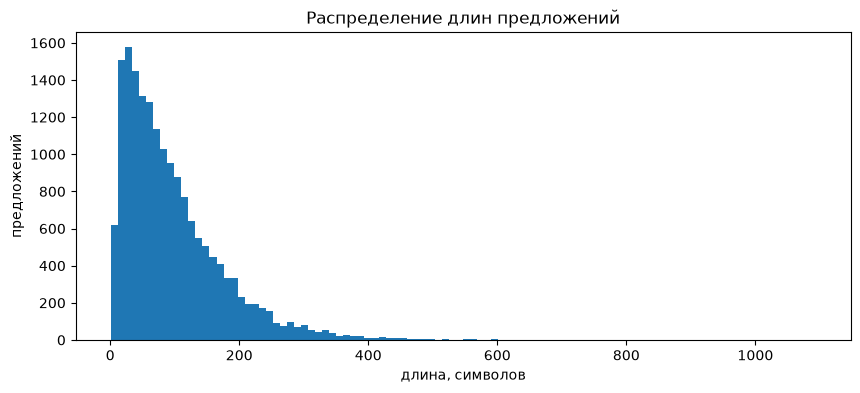

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(lengths, bins=100)
ax.set_title('Распределение длин предложений')
ax.set_xlabel('длина, символов')
ax.set_ylabel('предложений')
plt.show()

Самые частые словоформы. В маленьком корпусе из одной книги среди них будут имена героев.

In [8]:
print(', '.join(f'{word} ({count})' for word, count in word_counts.most_common(40)))

и (12913), не (6535), что (6139), в (5721), он (5549), на (3592), она (3433), с (3358), я (3217), как (2685), но (2580), его (2579), это (2231), то (2040), к (1984), ее (1804), все (1792), было (1656), так (1424), сказал (1412), а (1397), же (1324), ему (1253), о (1243), за (1204), левин (1134), только (1016), ты (992), по (942), у (914), был (900), когда (863), из (836), для (827), сказала (827), бы (822), да (819), от (813), теперь (812), вы (758)


Самые короткие строки — на них хорошо видны артефакты форматирования.

In [9]:
short_lines = sorted({text for text in ru_texts if len(text) <= 4})
print(f'Разных строк длиной до 4 символов: {len(short_lines)}')
print(short_lines)

Разных строк длиной до 4 символов: 42
['I', 'II', 'III', 'IV', 'IX', 'V', 'VI', 'VII', 'VIII', 'X', 'XI', 'XII', 'XIII', 'XIV', 'XIX', 'XV', 'XVI', 'XVII', 'XX', 'XXI', 'XXII', 'XXIV', 'XXIX', 'XXV', 'XXVI', 'XXX', 'XXXI', 'XXXV', 'А?', 'Бац!', 'Во!', 'Где?', 'Да!', 'Да.', 'Да?', 'Жив!', 'Иди.', 'Как?', 'Мха!', 'Нет.', 'Ну?', 'Я...']


**Набор символов.** Символ, которого нет в корпусе, токенизатор не сможет выучить и заменит на `[UNK]`.
Проверяем, какие символы кроме русских букв встречаются, и есть ли в корпусе символы, обычные для современных текстов.

In [10]:
char_counts = Counter(char for text in ru_texts for char in text)
other_chars = {
    char: count
    for char, count in char_counts.items()
    if not re.fullmatch(r'[а-яёА-ЯЁ ]', char)
}

print(f'Разных символов в корпусе: {len(char_counts)}')
print()
print('Кроме русских букв и пробела:')
print(', '.join(f'{char!r} ({count})' for char, count in Counter(other_chars).most_common()))

Разных символов в корпусе: 134

Кроме русских букв и пробела:
',' (39345), '-' (23550), '.' (19395), '?' (2331), '"' (1551), '!' (1544), ';' (1108), 'e' (715), ':' (706), 'a' (462), 'n' (362), 'I' (354), 's' (333), 'i' (304), 'X' (302), 'l' (267), 'r' (264), 't' (259), 'o' (241), 'm' (227), 'u' (218), ')' (158), 'd' (157), 'c' (153), '(' (151), 'V' (120), 'p' (114), "'" (79), 'h' (74), 'f' (60), 'b' (55), 'g' (47), 'v' (41), 'L' (40), 'M' (32), 'z' (28), 'j' (19), 'x' (18), 'y' (17), 'C' (17), 'q' (17), 'A' (16), 'P' (13), 'w' (10), 'D' (9), 'E' (9), '1' (8), 'k' (8), 'J' (7), 'B' (6), '8' (6), 'T' (5), 'N' (5), 'K' (5), '6' (5), 'Q' (5), 'O' (5), 'H' (4), 'U' (4), '2' (4), '3' (4), 'S' (3), '0' (3), 'R' (2), '7' (2), '5' (2), '9' (2), 'Z' (2), 'W' (2), '4' (1), 'F' (1), 'Y' (1)


In [11]:
modern_chars = ['ё', 'Ё', '—', '–', '«', '»', '…', '№', '%', '€']

pd.DataFrame({
    'символ': modern_chars,
    'раз в корпусе': [char_counts.get(char, 0) for char in modern_chars],
}).set_index('символ').T

символ,ё,Ё,—,–,«,»,…,№,%,€
раз в корпусе,0,0,0,0,0,0,0,0,0,0


**Что показал осмотр:**

- **Корпус маленький.** 17 496 предложений, 1.69 млн символов, ~270 тыс. слов. Из 32 809 разных словоформ 18 402 (56%) встречаются
  всего один раз: токенизатор не сможет выучить их целиком и будет собирать из кусочков. Для сравнения, токенизаторы RuBERT обучались
  на гигабайтах текстов.
- **По сути это одна книга, «Анна Каренина».** Среди 30 самых частых словоформ есть `левин`. Лексика — проза XIX века,
  современных слов вроде «загуглить» здесь нет и быть не может.
- **Артефакты форматирования:**
  - прямая речь оформлена двойным дефисом `--` вместо тире (поэтому `-` — второй по частоте символ после запятой);
  - заголовки глав римскими цифрами (`I`, `XIV`, `XXXV`) идут отдельными строками;
  - встречаются многоточия из 4–5 точек.
- **Латиница** — это французские и английские вставки в тексте Толстого. Это настоящий текст, а не мусор, поэтому её оставляем.
- **Пустых строк нет**, а 318 повторов — короткие реплики вроде «Да.» или «Ну?». Это нормальный текст, не ошибка.
- **Нет символов современного текста:** `ё` (в книге везде «е»: `ее` встречается 1 804 раза), тире `—`, кавычки `«»`, `…`, `№`, `%`, `€`,
  а цифр всего несколько десятков. Если ничего не сделать, токенизатор вернёт на них `[UNK]`. Это учтём при очистке и настройке токенизатора.

### 1.3 Очистка текста

Токенизатор выучит всё, что часто встречается в корпусе, в том числе мусор. Если оставить `--` или `XIV`,
в словаре появятся бесполезные токены, которые займут место полезных кусочков слов.

| Что делаем | Пример | Зачем |
|---|---|---|
| Unicode-нормализация NFC | `й` из двух кодов → один код | одна и та же буква не должна превращаться в два разных символа |
| `--` → `—` | `-- Да? -- спросил он` → `— Да? — спросил он` | артефакт перевода книги в простой текст; тире в прямой речи и дефис в словах (`кто-то`) должны быть разными символами |
| 3 и более точек → `...` | `Люби кататься.....` → `Люби кататься...` | иначе в словарь попадут `....` и `.....` как отдельные токены |
| схлопнуть пробелы, обрезать края | | косметика |
| удалить строки-заголовки глав | `XIV` | это не текст, а нумерация глав |
| удалить пустые строки | | после очистки строка может оказаться пустой |

**Чего не делаем, в отличие от классической предобработки текста для классификаторов:** не удаляем пунктуацию, не приводим к нижнему регистру,
не лемматизируем. Токенизатор должен работать с настоящим текстом: запятые, заглавные буквы и все формы слов —
ровно то, что потом придёт на вход модели. Лемматизация лишила бы нас главного: увидеть, выучит ли токенизатор окончания.

Латиницу (французские вставки) и повторы коротких реплик оставляем — это настоящий текст.

Сначала посчитаем, сколько строк содержат каждый артефакт.

In [12]:
ROMAN_HEADING = re.compile(r'[IVXLC]+\.?')

artifacts = {
    'двойной дефис --': lambda text: '--' in text,
    'заголовок главы (XIV)': lambda text: ROMAN_HEADING.fullmatch(text.strip()) is not None,
    'многоточие из 4+ точек': lambda text: re.search(r'\.{4,}', text) is not None,
    'двойные пробелы, пробелы по краям': lambda text: re.search(r'\s{2,}', text) is not None or text != text.strip(),
    'не в форме NFC': lambda text: not unicodedata.is_normalized('NFC', text),
}

pd.DataFrame(
    {'строк': {name: sum(1 for text in ru_texts if check(text)) for name, check in artifacts.items()}}
)

,строк
двойной дефис --,6209
заголовок главы (XIV),239
многоточие из 4+ точек,14
"двойные пробелы, пробелы по краям",0
не в форме NFC,0


Функция очистки одного предложения и проверка, нужно ли его выбросить.

In [13]:
def clean_text(text: str) -> str:
    text = unicodedata.normalize('NFC', text)
    text = re.sub(r'-{2,}', '—', text)
    text = re.sub(r'\.{3,}', '...', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()


def is_garbage(text: str) -> bool:
    return not text or ROMAN_HEADING.fullmatch(text) is not None


clean_texts = []
for text in ru_texts:
    cleaned = clean_text(text)
    if not is_garbage(cleaned):
        clean_texts.append(cleaned)

print(f'Было предложений:   {len(ru_texts):,}')
print(f'Удалено:            {len(ru_texts) - len(clean_texts):,}')
print(f'Осталось:           {len(clean_texts):,}')
print(f'Символов осталось:  {sum(len(text) for text in clean_texts):,}')

Было предложений:   17,496
Удалено:            239
Осталось:           17,257
Символов осталось:  1,682,232


Проверка «было → стало» на строках, которые очистка изменила.

In [14]:
changed = [(text, clean_text(text)) for text in ru_texts if clean_text(text) != text]

print(f'Изменено строк: {len(changed):,}')
pd.DataFrame(
    random.Random(RANDOM_STATE).sample(changed, 8),
    columns=['было', 'стало'],
)

Изменено строк: 6,216


,было,стало
0,"-- Да, я в тот же день уехал.","— Да, я в тот же день уехал."
1,"Дело сестричек (это было филантропическое, религиозно-патриотическое учреждение) пошло было прекрасно, но с этими го...","Дело сестричек (это было филантропическое, религиозно-патриотическое учреждение) пошло было прекрасно, но с этими го..."
2,"-- Здесь, в Москве?","— Здесь, в Москве?"
3,"""Разве я не знаю, что это -- бесконечное пространство и что оно не круглый свод?","""Разве я не знаю, что это — бесконечное пространство и что оно не круглый свод?"
4,"Сережа пронзительно, как это часто бывало с ним, вскрикнул: ""А, мама!"" -- и остановился в нерешительности: идти ли к...","Сережа пронзительно, как это часто бывало с ним, вскрикнул: ""А, мама!"" — и остановился в нерешительности: идти ли к ..."
5,"""И у него там тоже какая-то своя философия есть на службу своих наклонностей"", -- подумал он.","""И у него там тоже какая-то своя философия есть на службу своих наклонностей"", — подумал он."
6,"-- Ну, так она второй ангел, -- сказал князь улыбаясь. -- Она называет ангелом нумер первый mademoiselle Вареньку.","— Ну, так она второй ангел, — сказал князь улыбаясь. — Она называет ангелом нумер первый mademoiselle Вареньку."
7,-- Я удивляюсь родителям.,— Я удивляюсь родителям.


Повторная проверка: после очистки артефактов не осталось.

In [15]:
pd.DataFrame(
    {'строк после очистки': {name: sum(1 for text in clean_texts if check(text)) for name, check in artifacts.items()}}
)

,строк после очистки
двойной дефис --,0
заголовок главы (XIV),0
многоточие из 4+ точек,0
"двойные пробелы, пробелы по краям",0
не в форме NFC,0


### 1.4 Отложенная выборка

Откладываем 5% предложений, которые токенизатор не увидит при обучении. На них в разделе 4 честно посчитаем,
насколько мелко он режет незнакомый, но похожий текст. Та же идея, что train/test в классическом ML:
проверять модель на том, на чём она училась, нечестно — результат будет завышен.

In [16]:
HOLDOUT_SHARE = 0.05

shuffled_texts = clean_texts.copy()
random.Random(RANDOM_STATE).shuffle(shuffled_texts)

holdout_size = int(len(shuffled_texts) * HOLDOUT_SHARE)
holdout_texts = shuffled_texts[:holdout_size]
train_texts = shuffled_texts[holdout_size:]

print(f'Предложений для обучения токенизатора: {len(train_texts):,}')
print(f'Предложений отложено для проверки:     {len(holdout_texts):,}')

Предложений для обучения токенизатора: 16,395
Предложений отложено для проверки:     862


### 1.5 Генератор батчей

`train_from_iterator` из библиотеки `tokenizers` принимает **итератор**: тексты приходят порциями (батчами), и весь корпус
не обязан лежать в памяти одним списком. Функция с `yield` — это **генератор**: при каждом обращении она отдаёт следующий батч
и «замирает» до следующего запроса, не создавая копию всех данных.

Наш корпус занимает всего несколько мегабайт, поэтому очищенные тексты держим в списке, а генератор нарезает его на батчи.
Для корпусов в десятки гигабайт тексты читали бы с диска потоком (`load_dataset(..., streaming=True)`) и чистили на лету,
но интерфейс для токенизатора остался бы тем же: генератор, отдающий списки строк.

In [17]:
BATCH_SIZE = 1000


def batch_iterator(texts: list[str], batch_size: int = BATCH_SIZE):
    for start in range(0, len(texts), batch_size):
        yield texts[start:start + batch_size]


batches = batch_iterator(train_texts)
first_batch = next(batches)

print(f'Тип объекта: {type(batches).__name__}')
print(f'Предложений в первом батче: {len(first_batch)}')
print(f'Всего батчей: {sum(1 for _ in batch_iterator(train_texts))}')
print()
for text in first_batch[:3]:
    print('•', text)

Тип объекта: generator
Предложений в первом батче: 1000
Всего батчей: 17

• Посмотревшись в зеркало, Левин заметил, что он красен; но он был уверен, что не пьян, и пошел по ковровой лестнице вверх за Степаном Аркадьичем.
• Был десятый час, когда он во второй раз пришел к крыльцу Щербацких.
• Тут вдруг заговорило несколько голосов, и высокий дворянин с перстнем, все более и более озлобляясь, кричал громче и громче. Но нельзя было разобрать, что он говорил.


## 2. Обучение BPE-токенизатора

Токенизатор в библиотеке `tokenizers` собирается из деталей, каждая отвечает за свой этап:

```
текст → Normalizer → Pre-tokenizer → Model (BPE) → Post-processor → токены и id
                                                        Decoder: id → текст
```

| Деталь | Что делает |
|---|---|
| **Normalizer** | приводит текст к единому виду (Unicode, замены символов) |
| **Pre-tokenizer** | грубо режет текст на «слова»: по пробелам, отделяет знаки препинания и цифры |
| **Model** | сам алгоритм: режет каждое «слово» на подслова по выученному словарю |
| **Post-processor** | добавляет служебные токены, например `[CLS] ... [SEP]` |
| **Decoder** | собирает текст обратно из токенов |

Собираем детали по очереди, затем обучаем модель на корпусе.

### 2.1 Алгоритм: BPE

**BPE (Byte Pair Encoding)** строит словарь снизу вверх:
1. начальный словарь — все отдельные символы корпуса;
2. находим самую частую пару соседних токенов (например, `с` + `т`) и склеиваем её в новый токен `ст`;
3. повторяем, пока словарь не дорастёт до заданного размера.

Результат обучения — словарь и упорядоченный список слияний (merges). Новый текст режется применением тех же слияний в том же порядке.
BPE лежит в основе токенизаторов GPT, LLaMA, Qwen.

`continuing_subword_prefix='##'` помечает кусочки из середины и конца слова: `пере` `##дум` `##ал`. Так же делают токенизаторы RuBERT,
с которыми будем сравнивать, — таблицы сравнения будут читаться одинаково.

Пока модель пустая: ни словаря, ни слияний.

In [18]:
empty_tokenizer = Tokenizer(models.BPE(unk_token='[UNK]', continuing_subword_prefix='##'))

print(f'Токенов в словаре до обучения: {empty_tokenizer.get_vocab_size()}')

Токенов в словаре до обучения: 0


### 2.2 Normalizer

- **NFC** — Unicode-нормализация: одна буква всегда записана одним и тем же кодом.
- **`ё` → `е`.** В корпусе нет ни одной буквы `ё` (в книге везде «е»), поэтому токенизатор не выучил бы ни одного кусочка с ней,
  и любое слово с `ё` получило бы `[UNK]`. Нормализатор применяется и при обучении, и при каждом использовании токенизатора,
  поэтому `ёжик` во входном тексте превратится в `ежик`.
- **Регистр сохраняем.** Готовые токенизаторы RuBERT тоже различают регистр, а имена собственные без заглавной буквы теряют информацию.

In [19]:
ru_normalizer = normalizers.Sequence([
    normalizers.NFC(),
    normalizers.Replace('ё', 'е'),
    normalizers.Replace('Ё', 'Е'),
])

ru_normalizer.normalize_str('Её ёжик съел ещё яблоко')

'Ее ежик съел еще яблоко'

### 2.3 Pre-tokenizer

BPE склеивает символы только внутри одного куска, который выдал pre-tokenizer. Поэтому:
- **`WhitespaceSplit`** режет по пробелам — токен никогда не захватит два слова;
- **`Punctuation('isolated')`** отделяет каждый знак препинания. Без этого в словарь попали бы `сказал,` и `сказал.` —
  одно слово «размножилось» бы по знакам препинания;
- **`Digits(individual_digits=True)`** режет числа на отдельные цифры, чтобы не учить токены для каждого числа.

In [20]:
ru_pre_tokenizer = pre_tokenizers.Sequence([
    pre_tokenizers.WhitespaceSplit(),
    pre_tokenizers.Punctuation(behavior='isolated'),
    pre_tokenizers.Digits(individual_digits=True),
])

ru_pre_tokenizer.pre_tokenize_str('— Да?! — спросил он, улыбаясь в 1873 году.')

[('—', (0, 1)),
 ('Да', (2, 4)),
 ('?', (4, 5)),
 ('!', (5, 6)),
 ('—', (7, 8)),
 ('спросил', (9, 16)),
 ('он', (17, 19)),
 (',', (19, 20)),
 ('улыбаясь', (21, 29)),
 ('в', (30, 31)),
 ('1', (32, 33)),
 ('8', (33, 34)),
 ('7', (34, 35)),
 ('3', (35, 36)),
 ('году', (37, 41)),
 ('.', (41, 42))]

Каждый кусок возвращается вместе с позициями начала и конца в исходной строке (offsets).
`?` и `!` стали отдельными кусками, `1873` — четырьмя цифрами.

### 2.4 Гиперпараметры обучения (Trainer)

- **`vocab_size = 16 000`** — размер словаря. Задание предлагает 10–30 тыс. Наш корпус маленький: при `min_frequency=2`
  на нём набирается только около 24.6 тыс. токенов, дальше склеивать нечего. 16 тыс. — с запасом ниже этого потолка
  (влияние размера словаря проверим в разделе 4).
- **`min_frequency = 2`** — не склеивать пару, если она встретилась всего один раз: такое слияние не обобщается, это зазубривание.
- **Специальные токены** получат id 0–4:
  - `[PAD]` — заполнитель для выравнивания текстов в батче по длине;
  - `[UNK]` — неизвестный символ;
  - `[CLS]` — начало текста (в BERT его вектор описывает весь текст);
  - `[SEP]` — конец текста или граница между двумя текстами;
  - `[MASK]` — «закрытое» слово, которое BERT учится угадывать.
- **`initial_alphabet`** — символы, которые обязательно попадут в словарь, даже если их не было в корпусе: тире, кавычки-«ёлочки»,
  `…`, `№`, `%`, `€` и цифры. Знаки препинания pre-tokenizer всегда отделяет от слов, поэтому им достаточно быть в словаре как
  отдельным токенам. Для букв так не получится: внутри слова нужен вариант с префиксом (`##ё`), которого `initial_alphabet` не создаёт.
  Поэтому `ё` решили нормализатором.

In [21]:
VOCAB_SIZE = 16_000
MIN_FREQUENCY = 2
SPECIAL_TOKENS = ['[PAD]', '[UNK]', '[CLS]', '[SEP]', '[MASK]']
EXTRA_ALPHABET = list('—–«»„“”…№%€') + list('0123456789')

### 2.5 Обучение

Функция собирает все детали и обучает токенизатор через `train_from_iterator` на генераторе батчей из раздела 1.5.
Она пригодится ещё раз в разделе 4 для экспериментов с размером словаря и корпусом.

Параметр `handle_rare_chars=False` отключает замену `ё` и `initial_alphabet` — получится «голая» версия токенизатора,
на которой в разделе 4 будет видно, откуда берутся `[UNK]`.

In [22]:
def train_bpe_tokenizer(
    texts: list[str],
    vocab_size: int = VOCAB_SIZE,
    handle_rare_chars: bool = True,
) -> Tokenizer:
    tokenizer = Tokenizer(models.BPE(unk_token='[UNK]', continuing_subword_prefix='##'))
    tokenizer.normalizer = ru_normalizer if handle_rare_chars else normalizers.NFC()
    tokenizer.pre_tokenizer = ru_pre_tokenizer

    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        min_frequency=MIN_FREQUENCY,
        special_tokens=SPECIAL_TOKENS,
        initial_alphabet=EXTRA_ALPHABET if handle_rare_chars else [],
        continuing_subword_prefix='##',
        show_progress=False,
    )
    tokenizer.train_from_iterator(batch_iterator(texts), trainer=trainer, length=len(texts))

    tokenizer.post_processor = processors.TemplateProcessing(
        single='[CLS] $A [SEP]',
        pair='[CLS] $A [SEP] $B:1 [SEP]:1',
        special_tokens=[
            ('[CLS]', tokenizer.token_to_id('[CLS]')),
            ('[SEP]', tokenizer.token_to_id('[SEP]')),
        ],
    )
    tokenizer.decoder = decoders.WordPiece(prefix='##')
    return tokenizer


start = time.perf_counter()
ru_tokenizer = train_bpe_tokenizer(train_texts)
print(f'Обучение заняло {time.perf_counter() - start:.2f} с')
print(f'Размер словаря: {ru_tokenizer.get_vocab_size():,}')

ru_tokenizer_raw = train_bpe_tokenizer(train_texts, handle_rare_chars=False)
print(f'Размер словаря «голой» версии: {ru_tokenizer_raw.get_vocab_size():,}')

Обучение заняло 0.51 с
Размер словаря: 16,000


Размер словаря «голой» версии: 16,000


Обучение заняло меньше секунды: BPE не нейросеть, а подсчёт частот пар символов, а библиотека `tokenizers` написана на Rust.

Сравним основную и «голую» версии на фразе с символами, которых нет в корпусе.

In [23]:
rare_chars_example = 'Её ёжик съел 5 яблок — «№1» в рейтинге!'

pd.DataFrame({
    'основная': [' '.join(ru_tokenizer.encode(rare_chars_example, add_special_tokens=False).tokens)],
    '«голая»': [' '.join(ru_tokenizer_raw.encode(rare_chars_example, add_special_tokens=False).tokens)],
}, index=[rare_chars_example]).T

,Её ёжик съел 5 яблок — «№1» в рейтинге!
основная,Ее е ##жи ##к съ ##ел 5 я ##б ##лок — « № 1 » в рей ##тин ##ге !
«голая»,Е [UNK] [UNK] ##жи ##к съ ##ел [UNK] я ##б ##лок — [UNK] [UNK] 1 [UNK] в рей ##тин ##ге !


В «голой» версии `[UNK]` получили `ё`, `«»`, `№` и даже цифра `5`: в обучающей части корпуса её нет.
Тире `—` известно обеим версиям: оно появилось в корпусе после замены `--` → `—` при очистке.
Основная версия обходится без `[UNK]`: `ё` заменена нормализатором, остальные символы добавлены через `initial_alphabet`.

### 2.6 Post-processor и decoder

- **Post-processor** (`TemplateProcessing`) по шаблону `[CLS] $A [SEP]` сам добавляет служебные токены в начало и конец,
  как токенизаторы BERT. Если служебные токены не нужны, передаём `add_special_tokens=False`.
- **Decoder** (`WordPiece(prefix='##')`) собирает текст обратно: приклеивает `##`-кусочки к предыдущему токену.

Посмотрим, что выдаёт токенизатор для одного предложения: токены, их id в словаре и позиции в исходном тексте.

In [24]:
example = 'Левин перечитал её письмо и улыбнулся.'
encoding = ru_tokenizer.encode(example)

pd.DataFrame({
    'токен': encoding.tokens,
    'id': encoding.ids,
    'фрагмент исходного текста': [example[start:end] for start, end in encoding.offsets],
})

,токен,id,фрагмент исходного текста
0,[CLS],2,
1,Левин,367,Левин
2,перечитал,14756,перечитал
3,ее,311,её
4,письмо,1544,письмо
5,и,117,и
6,улыбнулся,2257,улыбнулся
7,.,13,.
8,[SEP],3,


In [25]:
print('input_ids:', encoding.ids)
print('decode:   ', ru_tokenizer.decode(encoding.ids))

input_ids: [2, 367, 14756, 311, 1544, 117, 2257, 13, 3]
decode:    Левин перечитал ее письмо и улыбнулся.


`input_ids` — это то, что получила бы нейросеть: только числа. `decode` вернул текст, но `её` стала `ее`:
нормализатор заменил букву ещё до токенизации, и в токенах её больше нет. А `фрагмент исходного текста` по-прежнему указывает на `её` —
offsets ссылаются на исходную строку.

Ещё одна особенность: pre-tokenizer выбрасывает информацию о пробелах, поэтому при декодировании вокруг некоторых знаков
пробелы могут не восстановиться (`« слово »`). У byte-level BPE (GPT) пробел хранится внутри токена, и такой проблемы нет.

### 2.7 Изучаем словарь

Начало словаря: специальные токены и алфавит.

In [26]:
id_to_token = {token_id: token for token, token_id in ru_tokenizer.get_vocab().items()}
vocab_size = ru_tokenizer.get_vocab_size()

print('Первые 60 токенов:')
print(' '.join(id_to_token[i] for i in range(60)))
print()
print('Последние 40 выученных токенов:')
print(' '.join(id_to_token[i] for i in range(vocab_size - 40, vocab_size)))

Первые 60 токенов:
[PAD] [UNK] [CLS] [SEP] [MASK] ! " % ' ( ) , - . 0 1 2 3 4 5 6 7 8 9 : ; ? A B C D E F H I J K L M N O P Q R S T U V W X Y Z a b c d e f g h

Последние 40 выученных токенов:
назначил запахнув примир приближаясь выпустила ножками ножницы предстоящих предстоящее местечки барином барыши приедете гроши грибах энергию энергией энергическое ##гнутые застрели мечтала мечтами питье питья освещении третье третья третьей закурив закусок Николаевну засмеялись возбуждения возбуждало возбуждении возбуждена возбужденным акком берег ветром


Как BPE строил словарь: первые слияния (самые частые пары в корпусе) и слияния из середины списка.

In [27]:
merges = json.loads(ru_tokenizer.to_str())['model']['merges']


def format_merge(merge) -> str:
    left, right = merge if isinstance(merge, list) else merge.split(' ')
    return f'{left} + {right}'


print(f'Всего слияний: {len(merges):,}')
print()
print('Первые 25:')
print(', '.join(format_merge(merge) for merge in merges[:25]))
print()
print('С 5000-го:')
print(', '.join(format_merge(merge) for merge in merges[5000:5025]))

Всего слияний: 15,779

Первые 25:
##т + ##о, ##а + ##л, ##н + ##о, ##с + ##т, н + ##е, ##е + ##н, ##г + ##о, п + ##о, ##р + ##о, ##н + ##а, ##е + ##л, ##в + ##о, ##т + ##ь, ##е + ##р, ##к + ##о, ##к + ##а, н + ##а, ##и + ##л, ##р + ##а, ч + ##то, ##е + ##т, ##о + ##л, б + ##ы, ##р + ##и, ##в + ##и

С 5000-го:
перед + ##ней, краси + ##вое, ##on + ##s, спи + ##ну, нежно + ##сти, рабо + ##чего, карет + ##ы, Ро + ##сси, мер + ##ы, нав + ##сегда, Варень + ##ки, Го + ##вор, друж + ##елю, куч + ##ер, прие + ##ду, строго + ##е, ар + ##тель, выбо + ##ры, причи + ##ны, старо + ##му, зал + ##ы, испо + ##р, испо + ##рт, пр + ##ер, услых + ##ала


Самые длинные токены — слова, которые корпус выучил целиком, и сколько в словаре начал слов и `##`-продолжений.

In [28]:
vocab = ru_tokenizer.get_vocab()
longest_tokens = sorted(vocab, key=lambda token: len(token.removeprefix('##')), reverse=True)[:30]
continuation_count = sum(1 for token in vocab if token.startswith('##'))

print('30 самых длинных токенов:')
print(', '.join(longest_tokens))
print()
print(f'Начала слов:           {vocab_size - continuation_count:,}')
print(f'Продолжения слов (##): {continuation_count:,}')

30 самых длинных токенов:
усовершенствования, превосходительство, действительностью, противоположность, неопределенность, несправедливость, действительность, действительности, остановившегося, государственной, Александровичем, необыкновенного, нерешительности, баллотироваться, преимущественно, последовательно, государственных, противопоставля, останавливаясь, туберкулезного, решительностью, неодобрительно, удовлетворения, представляться, замешательство, непростительно, обстоятельство, удовлетворение, справедливости, преждевременно

Начала слов:           12,563
Продолжения слов (##): 3,437


**Что видно в словаре:**

- **Первые слияния** — самые частые пары букв внутри слов: `##т + ##о`, `##а + ##л`, `##н + ##о`. Очень рано появляются
  короткие частые слова: `ч + ##то` → `что`.
- **Слияния из середины списка** часто склеивают основу и окончание или суффикс: `карет + ##ы`, `мер + ##ы`, `куч + ##ер`.
  Но граница не всегда проходит по морфемам: `причи + ##ны`, `старо + ##му`. BPE ничего не знает о морфологии,
  он склеивает то, что часто встречается рядом.
- **Самые длинные токены** — длинные частые слова книги: `превосходительство`, `Александровичем`, `баллотироваться`.
  Словарь отражает корпус, на котором обучен.
- **Начал слов в 3.7 раза больше, чем продолжений** (12 563 против 3 437). В конце обучения BPE добавляет целые словоформы,
  причём разные формы одного слова — отдельными токенами: `возбуждения`, `возбуждало`, `возбуждении`, `возбуждена`.
  Как это влияет на разбор новых слов, разберём в разделе 3.

### 2.8 Сохранение

Весь токенизатор — настройки всех деталей, словарь и слияния — сохраняется в один JSON-файл.
Загрузить его можно где угодно через `Tokenizer.from_file`, без повторного обучения.

In [29]:
TOKENIZER_DIR = Path('../tokenizer') if Path('../tokenizer').is_dir() else Path('tokenizer')
TOKENIZER_DIR.mkdir(exist_ok=True)
TOKENIZER_PATH = TOKENIZER_DIR / 'ru_bpe.json'

ru_tokenizer.save(str(TOKENIZER_PATH))
print(f'Сохранено: {TOKENIZER_PATH} ({TOKENIZER_PATH.stat().st_size / 1024:.0f} КБ)')

loaded_tokenizer = Tokenizer.from_file(str(TOKENIZER_PATH))
print('После загрузки id совпадают:', loaded_tokenizer.encode(example).ids == encoding.ids)

Сохранено: ../tokenizer/ru_bpe.json (1274 КБ)
После загрузки id совпадают: True
